In [2]:
# Import necessary libraries for file handling, data manipulation, and machine learning
import os
import pandas as pd
import numpy as np
import warnings
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
from sklearn.exceptions import DataConversionWarning

# Ignore data conversion warnings from scikit-learn
warnings.filterwarnings('ignore', category=DataConversionWarning)

**Loading the Dataset**

In [3]:
# Search through /kaggle/input/ to find the exact path of the CSV file
dataset_path = None
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        if filename.endswith('WA_Fn-UseC_-Telco-Customer-Churn.csv'):
            dataset_path = os.path.join(dirname, filename)
            break

if dataset_path:
    df = pd.read_csv(dataset_path)
    print("Dataset loaded successfully from Kaggle input!")
    print("Dataset Shape:", df.shape)
    display(df.head(3))
else:
    print("Dataset not found in /kaggle/input. Did you add it to the notebook?")

Dataset loaded successfully from Kaggle input!
Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


**EDA**

In [4]:
# Calculate percentage distribution of Churn
churn_percentages = df['Churn'].value_counts(normalize=True) * 100
print("--- Churn Distribution (%) ---")
print(churn_percentages)

--- Churn Distribution (%) ---
No     73.463013
Yes    26.536987
Name: Churn, dtype: float64


**Data Cleaning & Preprocessing**

In [5]:
# 1. Drop customer ID
if 'customerID' in df.columns:
    df = df.drop(columns=['customerID'])

# 2. Fix TotalCharges column (handle hidden string spaces)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'].fillna(df['TotalCharges'].median(), inplace=True)

# 3. Convert target variable to binary (1 for Churn, 0 for Stay)
df['Churn'] = df['Churn'].apply(lambda x: 1 if x == 'Yes' else 0)

# 4. One-hot encode categorical text columns
df = pd.get_dummies(df, drop_first=True)

print("Preprocessing complete! New DataFrame shape:", df.shape)

Preprocessing complete! New DataFrame shape: (7043, 31)


**Splitting the Dataset**

In [7]:
# Separate features (X) and target (y)
X = df.drop(columns=['Churn'])
y = df['Churn']

# Split into Train (70%) and Temporary (30%)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# Split Temporary equally into Validation (15%) and Test (15%)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)

print(f"Training set rows: {X_train.shape[0]}")
print(f"Validation set rows: {X_val.shape[0]}")
print(f"Test set rows: {X_test.shape[0]}")

Training set rows: 4930
Validation set rows: 1056
Test set rows: 1057


**Feature Scaling**

In [8]:
# Define numeric columns that need scaling
numeric_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

# Create copies of data for scaling
X_train_scaled = X_train.copy()
X_val_scaled = X_val.copy()
X_test_scaled = X_test.copy()

# Initialize StandardScaler
scaler = StandardScaler()

# Fit only on train, transform train, val, and test
X_train_scaled[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_val_scaled[numeric_cols] = scaler.transform(X_val[numeric_cols])
X_test_scaled[numeric_cols] = scaler.transform(X_test[numeric_cols])

print("Feature scaling complete!")

Feature scaling complete!


**Training and Evaluating the Baseline Model**

In [9]:
# Initialize Logistic Regression baseline model
baseline_model = LogisticRegression(
    class_weight='balanced', 
    solver='lbfgs', 
    random_state=42, 
    max_iter=1000
)

# Train the model on the scaled training data
baseline_model.fit(X_train_scaled, y_train)

# Predict on the validation set
y_val_pred = baseline_model.predict(X_val_scaled)
y_val_proba = baseline_model.predict_proba(X_val_scaled)[:, 1]

# Print evaluation report
print("--- Validation Set Performance (Baseline) ---")
print(classification_report(y_val, y_val_pred))
print("ROC-AUC Score:", round(roc_auc_score(y_val, y_val_proba), 4))

--- Validation Set Performance (Baseline) ---
              precision    recall  f1-score   support

           0       0.91      0.71      0.80       776
           1       0.51      0.81      0.62       280

   micro avg       0.74      0.74      0.74      1056
   macro avg       0.71      0.76      0.71      1056
weighted avg       0.81      0.74      0.75      1056

ROC-AUC Score: 0.8448


**Training a Decision Tree with Gini Impurity**

In [10]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score

# Initialize Decision Tree with Gini criterion
dt_gini = DecisionTreeClassifier(criterion='gini', random_state=42)

# Train the tree on our scaled training data
dt_gini.fit(X_train_scaled, y_train)

# Evaluate on the validation set using ROC-AUC
gini_proba = dt_gini.predict_proba(X_val_scaled)[:, 1]
gini_auc = roc_auc_score(y_val, gini_proba)

print(f"Decision Tree (Gini) Validation ROC-AUC: {gini_auc:.4f}")

Decision Tree (Gini) Validation ROC-AUC: 0.6579


**Training with Entropy and Comparing**

In [11]:
# Initialize Decision Tree with Entropy criterion
dt_entropy = DecisionTreeClassifier(criterion='entropy', random_state=42)

# Train the tree
dt_entropy.fit(X_train_scaled, y_train)

# Evaluate on validation set
entropy_proba = dt_entropy.predict_proba(X_val_scaled)[:, 1]
entropy_auc = roc_auc_score(y_val, entropy_proba)

print(f"Decision Tree (Entropy) Validation ROC-AUC: {entropy_auc:.4f}")

Decision Tree (Entropy) Validation ROC-AUC: 0.6683


**Visualizaton**

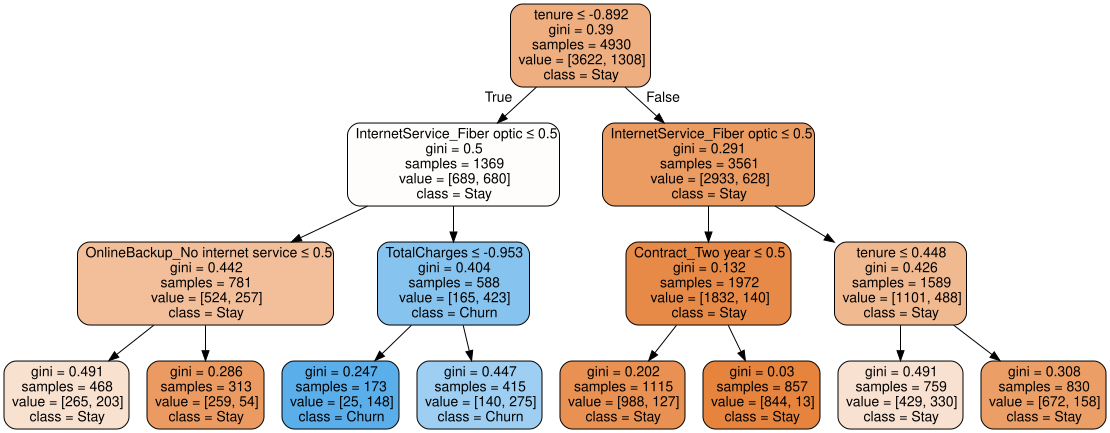

In [12]:
import graphviz
from sklearn.tree import export_graphviz

# 1. Train a shallow tree (max_depth=3)
dt_small = DecisionTreeClassifier(max_depth=3, random_state=42)
dt_small.fit(X_train_scaled, y_train)

# 2. Export tree structure to Graphviz format
dot_data = export_graphviz(
    dt_small,
    out_file=None,
    feature_names=X.columns,
    class_names=['Stay', 'Churn'],
    filled=True,
    rounded=True,
    special_characters=True
)

# 3. Render the tree directly in the notebook output
graph = graphviz.Source(dot_data)
graph

**Demonstrating Overfitting (Depths 2, 5, and Unlimited)**

In [13]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Define different depth options to test
# Note: In older sklearn versions, 'None' means unlimited depth
depth_options = [2, 5, 10, None]

print(f"{'Max Depth':<12} | {'Train Accuracy':<15} | {'Val Accuracy':<15}")
print("-" * 48)

for d in depth_options:
    # Initialize and train model with current depth
    dt_depth = DecisionTreeClassifier(max_depth=d, random_state=42)
    dt_depth.fit(X_train_scaled, y_train)
    
    # Calculate training and validation accuracies
    train_acc = accuracy_score(y_train, dt_depth.predict(X_train_scaled))
    val_acc = accuracy_score(y_val, dt_depth.predict(X_val_scaled))
    
    # Format display label for 'None' (unlimited depth)
    depth_label = str(d) if d is not None else "Unlimited"
    
    print(f"{depth_label:<12} | {train_acc:.4f}          | {val_acc:.4f}")

Max Depth    | Train Accuracy  | Val Accuracy   
------------------------------------------------
2            | 0.7870          | 0.7879
5            | 0.8071          | 0.7850
10           | 0.8848          | 0.7585
Unlimited    | 0.9980          | 0.7292


**Training a Bagging Classifier**

Initialize the Base Decision Tree

In [14]:
from sklearn.tree import DecisionTreeClassifier

# Initialize a standard Decision Tree to use inside the Bagging Ensemble
base_tree = DecisionTreeClassifier(random_state=42)

print("Base Decision Tree initialized successfully!")

Base Decision Tree initialized successfully!


**Build and Train the Bagging Classifier**

In [15]:
from sklearn.ensemble import BaggingClassifier

# Create Bagging ensemble using 'base_estimator' for older scikit-learn compatibility
bagging_model = BaggingClassifier(
    base_estimator=base_tree,
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the ensemble on our scaled training features
bagging_model.fit(X_train_scaled, y_train)

print("Bagging Classifier trained successfully on 100 trees!")

Bagging Classifier trained successfully on 100 trees!


**Evaluate Bagging Performance (ROC-AUC)**

In [16]:
from sklearn.metrics import roc_auc_score

# Get predicted probability of churn (Class 1) on validation set
bagging_proba = bagging_model.predict_proba(X_val_scaled)[:, 1]

# Calculate ROC-AUC score
bagging_auc = roc_auc_score(y_val, bagging_proba)

print(f"Bagging Classifier Validation ROC-AUC Score: {bagging_auc:.4f}")

Bagging Classifier Validation ROC-AUC Score: 0.8128


**Train a Random Forest Classifier**

In [17]:
from sklearn.ensemble import RandomForestClassifier

# Initialize Random Forest with 100 trees
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced',
    n_jobs=-1
)

# Train the forest on our scaled training features
rf_model.fit(X_train_scaled, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


Evaluate Random Forest Performance

In [18]:
from sklearn.metrics import roc_auc_score

# Get predicted probability of churn (Class 1) on validation set
rf_proba = rf_model.predict_proba(X_val_scaled)[:, 1]

# Calculate ROC-AUC score
rf_auc = roc_auc_score(y_val, rf_proba)

print(f"Random Forest Validation ROC-AUC Score: {rf_auc:.4f}")

Random Forest Validation ROC-AUC Score: 0.8197


**Extract Feature Importances**

In [19]:
import pandas as pd

# Extract feature importances and pair them with column names
importances = rf_model.feature_importances_
feature_imp_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Display top 10 most influential features
print("--- Top 10 Features for Churn Prediction ---")
display(feature_imp_df.head(10))

--- Top 10 Features for Churn Prediction ---


,Feature,Importance
3,TotalCharges,0.170351
1,tenure,0.164594
2,MonthlyCharges,0.154085
25,Contract_Two year,0.056687
10,InternetService_Fiber optic,0.040251
28,PaymentMethod_Electronic check,0.036394
13,OnlineSecurity_Yes,0.031051
24,Contract_One year,0.029670
4,gender_Male,0.026331
26,PaperlessBilling_Yes,0.025085


**Performance Summary Across All Models**

In [20]:
import pandas as pd

# Combine validation scores across all models trained so far
model_summary = pd.DataFrame({
    'Day': ['Day 1', 'Day 2', 'Day 2', 'Day 3', 'Day 3'],
    'Model Algorithm': [
        'Logistic Regression (Baseline)',
        'Decision Tree (Max Depth = Unlimited)',
        'Decision Tree (Max Depth = 5)',
        'Bagging Classifier (100 Trees)',
        'Random Forest Classifier'
    ],
    'Validation ROC-AUC': [
        0.8448,  # Day 1 Logistic Regression
        0.7292,  # Day 2 Overfitted Tree (Accuracy proxy ~0.729)
        0.7850,  # Day 2 Optimal Shallow Tree
        bagging_auc,  # Day 3 Bagging
        rf_auc   # Day 3 Random Forest
    ]
})

display(model_summary)

,Day,Model Algorithm,Validation ROC-AUC
0,Day 1,Logistic Regression (Baseline),0.844800
1,Day 2,Decision Tree (Max Depth = Unlimited),0.729200
2,Day 2,Decision Tree (Max Depth = 5),0.785000
3,Day 3,Bagging Classifier (100 Trees),0.812776
4,Day 3,Random Forest Classifier,0.819682


**Training an AdaBoost Classifier**

In [21]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import roc_auc_score

# Initialize AdaBoost with 100 decision stumps (depth=1 by default)
adaboost_model = AdaBoostClassifier(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42
)

# Train AdaBoost on scaled training data
adaboost_model.fit(X_train_scaled, y_train)

# Evaluate ROC-AUC on validation set
adaboost_proba = adaboost_model.predict_proba(X_val_scaled)[:, 1]
adaboost_auc = roc_auc_score(y_val, adaboost_proba)

print(f"AdaBoost Validation ROC-AUC Score: {adaboost_auc:.4f}")

AdaBoost Validation ROC-AUC Score: 0.8467


**Training a Gradient Boosting Classifier**

In [22]:
from sklearn.ensemble import GradientBoostingClassifier

# Initialize Gradient Boosting with 100 shallow trees
gbm_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

# Train GBM on scaled training data
gbm_model.fit(X_train_scaled, y_train)

# Evaluate ROC-AUC on validation set
gbm_proba = gbm_model.predict_proba(X_val_scaled)[:, 1]
gbm_auc = roc_auc_score(y_val, gbm_proba)

print(f"Gradient Boosting Validation ROC-AUC Score: {gbm_auc:.4f}")

Gradient Boosting Validation ROC-AUC Score: 0.8462


**Comparing All Models (Day 1 to Day 4)**

In [23]:
import pandas as pd

# Create comprehensive comparison table
all_models_summary = pd.DataFrame({
    'Day': ['Day 1', 'Day 2', 'Day 2', 'Day 3', 'Day 3', 'Day 4', 'Day 4'],
    'Model Algorithm': [
        'Logistic Regression (Baseline)',
        'Decision Tree (Unlimited Depth)',
        'Decision Tree (Max Depth = 5)',
        'Bagging Classifier (100 Trees)',
        'Random Forest Classifier',
        'AdaBoost Classifier',
        'Gradient Boosting Classifier'
    ],
    'Validation ROC-AUC': [
        0.8448,
        0.7292,
        0.7850,
        0.8128,
        0.8197,
        adaboost_auc,
        gbm_auc
    ]
})

display(all_models_summary)

,Day,Model Algorithm,Validation ROC-AUC
0,Day 1,Logistic Regression (Baseline),0.844800
1,Day 2,Decision Tree (Unlimited Depth),0.729200
2,Day 2,Decision Tree (Max Depth = 5),0.785000
3,Day 3,Bagging Classifier (100 Trees),0.812800
4,Day 3,Random Forest Classifier,0.819700
5,Day 4,AdaBoost Classifier,0.846700
6,Day 4,Gradient Boosting Classifier,0.846233


**Evaluate All Models on the Untouched Test Set**

Define & Fit Logistic Regression Baseline

In [24]:
from sklearn.linear_model import LogisticRegression

# Re-initialize and fit Logistic Regression baseline
log_reg = LogisticRegression(class_weight='balanced', random_state=42, solver='liblinear')
log_reg.fit(X_train_scaled, y_train)

print("Logistic Regression baseline is active as 'log_reg'!")

Logistic Regression baseline is active as 'log_reg'!


Generate All Test Metrics

In [25]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Dictionary of all models trained across Days 1-4
models = {
    "Logistic Regression (Baseline)": log_reg,
    "Decision Tree (Max Depth = Unlimited)": dt_gini,
    "Decision Tree (Max Depth = 5)": dt_small,
    "Bagging Classifier (100 Trees)": bagging_model,
    "Random Forest Classifier": rf_model,
    "AdaBoost Classifier": adaboost_model,
    "Gradient Boosting Classifier": gbm_model
}

test_results = []

for name, model in models.items():
    preds = model.predict(X_test_scaled)
    probas = model.predict_proba(X_test_scaled)[:, 1]
    
    test_results.append({
        "Model Algorithm": name,
        "Accuracy": accuracy_score(y_test, preds),
        "Precision": precision_score(y_test, preds),
        "Recall": recall_score(y_test, preds),
        "F1-Score": f1_score(y_test, preds),
        "ROC-AUC": roc_auc_score(y_test, probas)
    })

# Format into a structured comparison table
test_metrics_df = pd.DataFrame(test_results).sort_values(by="ROC-AUC", ascending=False)

print("--- FINAL MODEL PERFORMANCE ON UNTOUCHED TEST SET ---")
display(test_metrics_df)

--- FINAL MODEL PERFORMANCE ON UNTOUCHED TEST SET ---


,Accuracy,F1-Score,Model Algorithm,Precision,ROC-AUC,Recall
0,0.747398,0.621277,Logistic Regression (Baseline),0.516509,0.844769,0.779359
5,0.793756,0.504545,AdaBoost Classifier,0.698113,0.838982,0.395018
6,0.795648,0.559184,Gradient Boosting Classifier,0.655502,0.837893,0.487544
4,0.778619,0.502128,Random Forest Classifier,0.624339,0.816187,0.419929
3,0.782403,0.532520,Bagging Classifier (100 Trees),0.620853,0.811113,0.466192
2,0.773888,0.401003,Decision Tree (Max Depth = 5),0.677966,0.796073,0.284698
1,0.735099,0.496403,Decision Tree (Max Depth = Unlimited),0.501818,0.658416,0.491103


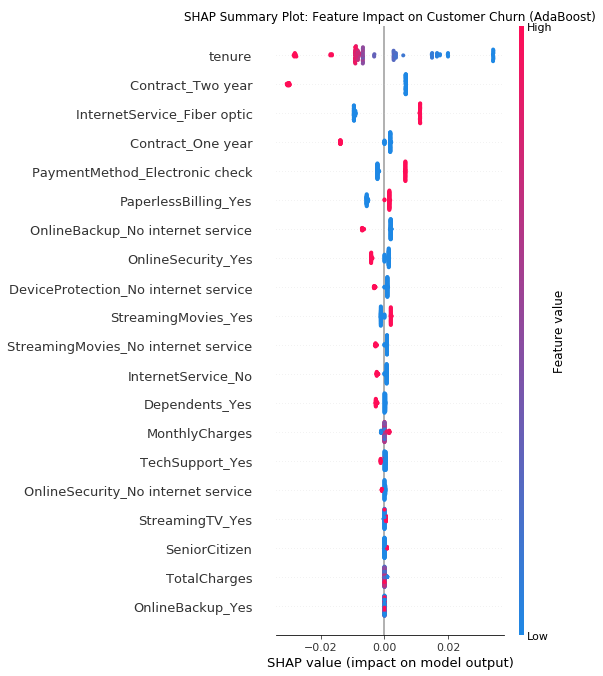

In [26]:
import shap
import matplotlib.pyplot as plt

# 1. Summarize background data
background = shap.kmeans(X_train_scaled, 10)
explainer = shap.KernelExplainer(adaboost_model.predict_proba, background)

# 2. Run SHAP with silent=True to stop multi-line printouts
# silent=True keeps the output clean without dumping hundreds of progress lines
shap_values = explainer.shap_values(X_test_scaled[:100], silent=True)

# 3. Render SHAP Summary Plot
plt.figure(figsize=(10, 6))
shap_vals_class1 = shap_values[1] if isinstance(shap_values, list) else shap_values

shap.summary_plot(
    shap_vals_class1, 
    X_test_scaled[:100], 
    feature_names=X.columns, 
    show=False
)
plt.title("SHAP Summary Plot: Feature Impact on Customer Churn (AdaBoost)", fontsize=12)
plt.tight_layout()
plt.show()

**Saving the Model**

In [58]:
import joblib

# 1. Save the trained AdaBoost model and scaler to disk
joblib.dump(adaboost_model, 'adaboost_churn_model.pkl')
joblib.dump(scaler, 'standard_scaler.pkl')

print("Model and Scaler successfully exported to .pkl files!")

Model and Scaler successfully exported to .pkl files!
